# Correction — Python, NumPy et Pandas

**Question.** Comment comparer deux groupes de mesures simulées sans réduire toute l'information à une moyenne ? La correction utilise une graine fixe et explicite les dimensions avant l'agrégation.

## Comprendre la première cellule

`values.shape == (12,)` et `categories.shape == (12,)` : chaque catégorie correspond à une mesure. `frame` a donc douze lignes. `values.std()` utilise la dispersion de la population présente (`ddof=0`) ; pour une estimation d'échantillon, on utiliserait `ddof=1`. Le `boxplot` résume médiane et quartiles mais peut cacher les points individuels.

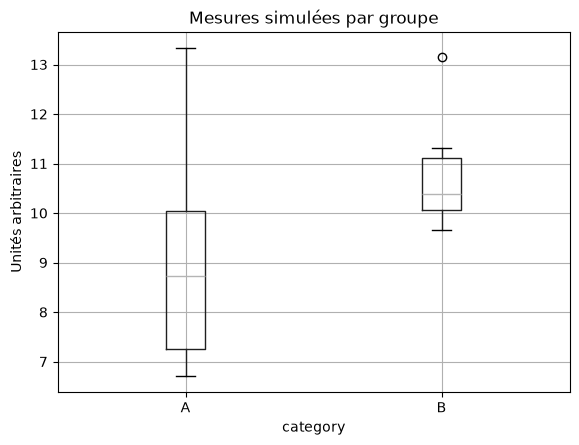

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng = np.random.default_rng(4)
values = rng.normal(10, 2, 12)
categories = np.array(['A', 'B'] * 6)
print('mean/std:', values.mean().round(2), values.std().round(2))
frame = pd.DataFrame({'category': categories, 'measurement': values})
print(frame.groupby('category')['measurement'].agg(['mean', 'count']))
frame.boxplot(column='measurement', by='category')
plt.title('Mesures simulées par groupe'); plt.suptitle(''); plt.ylabel('Unités arbitraires'); plt.show()
# The sample is small and simulated; a difference is not evidence about real groups.


## Voir les mesures et leur moyenne ensemble

Le graphique affiche chaque point, puis la moyenne par groupe calculée avec Pandas. Si les moyennes diffèrent, examinez aussi les étendues et le nombre d'observations. Douze points simulés ne justifient pas une inférence sur de vraies populations.

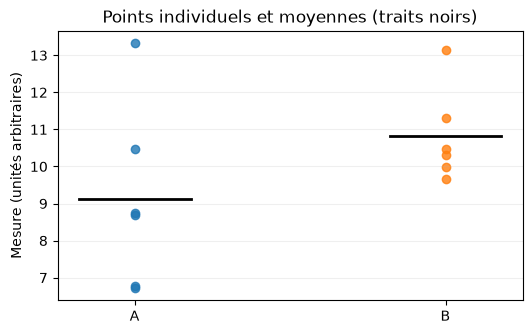

In [ ]:
group_mean = frame.groupby('category')['measurement'].mean()
fig, ax = plt.subplots(figsize=(6, 3.5))
for index, category in enumerate(['A', 'B']):
    group_values = frame.loc[frame.category == category, 'measurement']
    ax.scatter(np.full(len(group_values), index), group_values, alpha=0.8, label=f'Valeurs {category}')
    ax.plot([index - 0.18, index + 0.18], [group_mean[category]] * 2, color='black', linewidth=2)
ax.set(xticks=[0, 1], xticklabels=['A', 'B'], ylabel='Mesure (unités arbitraires)', title='Points individuels et moyennes (traits noirs)')
ax.grid(axis='y', alpha=0.2)
plt.show()

## Interprétation et limite

La moyenne résume un centre ; elle n'indique pas seule la dispersion. Le graphique permet de vérifier que les observations d'un même groupe se chevauchent ou non. Les catégories et valeurs étant simulées, la différence éventuelle n'a pas de signification empirique.